## Partie 1 — Explorer et vérifier les données

In [1]:
import pandas as pd

df = pd.read_csv("transactions_TP2.csv")

display(df.head())

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [2]:
df.shape

(3045, 12)

In [3]:
df.dtypes

id_operation            str
id_client               str
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                   str
appareil                str
region                  str
international           str
resultat_enquete        str
fraude                int64
dtype: object

In [4]:
# Nombre de valeurs manquantes
nombre = df.isnull().sum()

# Pourcentage de valeurs manquantes
pourcentage = (df.isnull().mean() * 100)

# Créer un tableau
missing = pd.DataFrame({
    'Nombre': nombre,
    'Pourcentage': pourcentage
})

# Trier du plus grand au plus petit
missing = missing.sort_values(
    by='Pourcentage',
    ascending=False
)

print(missing.round(2))

                  Nombre  Pourcentage
canal                159         5.22
anciennete_mois      137         4.50
appareil             122         4.01
montant_dh           110         3.61
region               103         3.38
nb_ops_24h            53         1.74
id_operation           0         0.00
id_client              0         0.00
heure                  0         0.00
international          0         0.00
resultat_enquete       0         0.00
fraude                 0         0.00


In [5]:
n_dup = df['id_operation'].duplicated().sum()

In [6]:
df[df['id_operation'].duplicated()]

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
327,OP00094,C10513,489.10,92.0,2.0,2,application,mobile,Casablanca-Settat,non,aucune_fraude,0
529,OP01772,C10234,2079.31,129.0,3.0,7,site_web,terminal,Casablanca-Settat,non,aucune_fraude,0
643,OP01970,C10747,375.69,135.0,1.0,19,NaN,NaN,Casablanca-Settat,non,fraude_confirmee,1
895,OP02169,C10048,19658.42,77.0,1.0,11,application,mobile,Autre,non,aucune_fraude,0
1111,OP02805,C10598,750.58,77.0,1.0,22,site_web,mobile,Autre,oui,fraude_confirmee,1
1193,OP01900,C10082,1037.87,105.0,2.0,23,application,mobile,Autre,non,aucune_fraude,0
1268,OP02099,C10733,967.82,129.0,2.0,21,application,ordinateur,Autre,non,aucune_fraude,0
1312,OP00082,C10337,611.42,135.0,3.0,11,site_web,ordinateur,Casablanca-Settat,non,aucune_fraude,0
1320,OP02049,C10201,2709.33,17.0,7.0,6,NaN,mobile,Casablanca-Settat,non,fraude_confirmee,1
1452,OP02697,C10193,251.61,31.0,2.0,0,application,mobile,Casablanca-Settat,non,fraude_confirmee,1


In [7]:
df[df['id_operation'].duplicated(keep=False)]

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
120,OP00311,C10104,306.78,93.0,3.0,20,site_web,terminal,Casablanca-Settat,non,aucune_fraude,0
122,OP01817,C10290,2472.69,12.0,4.0,3,site_web,mobile,Casablanca-Settat,non,aucune_fraude,0
202,OP01482,C10253,727.90,34.0,2.0,0,site_web,ordinateur,Marrakech-Safi,non,aucune_fraude,0
262,OP00094,C10513,489.10,92.0,2.0,2,application,mobile,Casablanca-Settat,non,aucune_fraude,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2793,OP02402,C10243,938.90,173.0,3.0,17,site_web,ordinateur,Marrakech-Safi,non,aucune_fraude,0
2799,OP01233,C10372,933.15,118.0,1.0,12,site_web,terminal,Draa-Tafilalet,non,aucune_fraude,0
2824,OP01394,C10577,1396.10,45.0,6.0,9,agence,mobile,NaN,non,aucune_fraude,0
2991,OP00365,C10697,198.52,43.0,3.0,5,site_web,ordinateur,Draa-Tafilalet,non,aucune_fraude,0


In [8]:
df = df.drop_duplicates(subset='id_operation')

In [9]:
print("Nombre de lignes avant :", 3045)

print("Nombre de lignes après :", len(df))

print("Nombre de doublons restants :",
      df['id_operation'].duplicated().sum())

Nombre de lignes avant : 3045
Nombre de lignes après : 3000
Nombre de doublons restants : 0


4. Tracez un histogramme du montant et un boxplot. Repérez quelques montants extrêmes. Faut-il
forcément les supprimer ? Justifiez votre réponse.

In [10]:
df['montant_dh'].describe()

count     2893.000000
mean      1028.359457
std       1320.830647
min         36.410000
25%        389.530000
50%        708.660000
75%       1249.480000
max      33281.230000
Name: montant_dh, dtype: float64

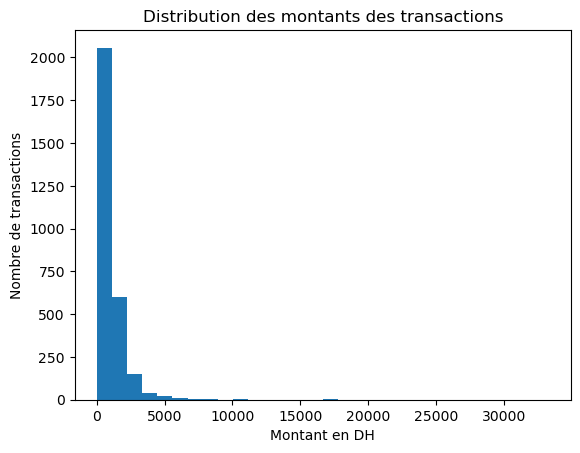

In [11]:
import matplotlib.pyplot as plt

# Ignorer les valeurs manquantes
montants = df['montant_dh'].dropna()

# Créer l'histogramme
plt.hist(montants, bins=30)

# Ajouter le titre et les noms des axes
plt.title("Distribution des montants des transactions")
plt.xlabel("Montant en DH")
plt.ylabel("Nombre de transactions")

# Afficher le graphique
plt.show()

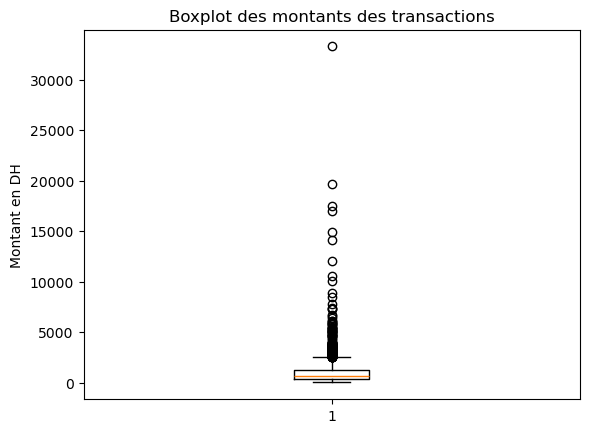

In [12]:
plt.boxplot(montants)

plt.title("Boxplot des montants des transactions")
plt.ylabel("Montant en DH")

plt.show()

5. Calculez la proportion de fraudes (fraude = 1) et tracez un diagramme des deux classes. Le fichier
est-il équilibré ? Pourquoi est-ce important pour préparer les données ?


fraude
0    2742
1     258
Name: count, dtype: int64
fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


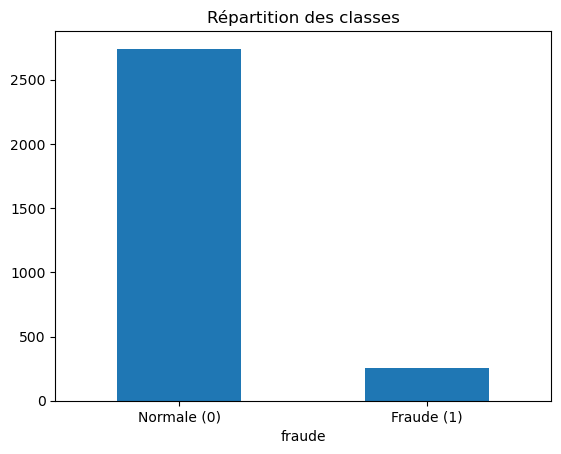

In [13]:
print(df["fraude"].value_counts())
print(df["fraude"].value_counts(normalize=True).round(4) * 100)

df["fraude"].value_counts().plot(kind="bar")
plt.title("Répartition des classes")
plt.xticks([0, 1], ["Normale (0)", "Fraude (1)"], rotation=0)
plt.show()

In [14]:
print(pd.crosstab(df["resultat_enquete"], df["fraude"]))

fraude               0    1
resultat_enquete           
aucune_fraude     2742    0
fraude_confirmee     0  258


## Partie 2 — Préparer les données sans fuite

In [16]:
from sklearn.model_selection import train_test_split

# Q7 : on retire les identifiants, resultat_enquete (fuite) et la cible
X = df.drop(columns=["id_operation", "id_client", "resultat_enquete", "fraude"])
y = df["fraude"]

print("X :", X.shape, "| y :", y.shape)

# Q8 : 80 % référence / 20 % vérification, en gardant la même proportion de fraudes
X_ref, X_ver, y_ref, y_ver = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print("Groupe de référence :", X_ref.shape)
print("Groupe de vérification :", X_ver.shape)

print("Taille de y_ref :", y_ref.shape)
print("Taille de y_verif :", y_ver.shape)

print("Fraude (global)      :", round(y.mean() * 100, 2), "%")
print("Fraude (référence)   :", round(y_ref.mean() * 100, 2), "%")
print("Fraude (vérification):", round(y_ver.mean() * 100, 2), "%")

X : (3000, 8) | y : (3000,)
Groupe de référence : (2400, 8)
Groupe de vérification : (600, 8)
Taille de y_ref : (2400,)
Taille de y_verif : (600,)
Fraude (global)      : 8.6 %
Fraude (référence)   : 8.58 %
Fraude (vérification): 8.67 %


In [17]:
num_cols = X_ref.select_dtypes(include="number").columns.tolist()
cat_cols = X_ref.select_dtypes(exclude="number").columns.tolist()

print("Numériques  :", num_cols)
print("Catégorielles :", cat_cols)

Numériques  : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Catégorielles : ['canal', 'appareil', 'region', 'international']


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Q10 : nombres = médiane puis StandardScaler
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Q11 : catégories = valeur la plus fréquente puis one-hot
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [19]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

# fit uniquement sur la référence
Xt_ref = preprocessor.fit_transform(X_ref)
# transform seulement (pas de fit) sur la vérification
Xt_ver = preprocessor.transform(X_ver)

print("Référence    :", X_ref.shape, "->", Xt_ref.shape)
print("Vérification :", X_ver.shape, "->", Xt_ver.shape)

Référence    : (2400, 8) -> (2400, 18)
Vérification : (600, 8) -> (600, 18)


In [20]:
from sklearn.preprocessing import RobustScaler

num_pipe_rob = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

prep_std = ColumnTransformer([("num", num_pipe, num_cols)]).set_output(transform="pandas")
prep_rob = ColumnTransformer([("num", num_pipe_rob, num_cols)]).set_output(transform="pandas")

std_ref = prep_std.fit_transform(X_ref)
rob_ref = prep_rob.fit_transform(X_ref)

# une opération ordinaire (proche de la médiane) et la plus élevée
idx_ord = (X_ref["montant_dh"] - X_ref["montant_dh"].median()).abs().idxmin()
idx_max = X_ref["montant_dh"].idxmax()

comparaison = pd.DataFrame({
    "montant_dh": X_ref.loc[[idx_ord, idx_max], "montant_dh"],
    "Standard": std_ref.loc[[idx_ord, idx_max], "num__montant_dh"],
    "Robust": rob_ref.loc[[idx_ord, idx_max], "num__montant_dh"],
}, index=["ordinaire", "très élevée"])
print(comparaison)

             montant_dh  Standard  Robust
ordinaire           NaN       NaN     NaN
très élevée         NaN       NaN     NaN


## Partie 3 — Comparer les méthodes de mise à l’échelle

question 15 et 16

In [21]:
m_ref = X_ref["montant_dh"]

Q1 = m_ref.quantile(0.25)
Q3 = m_ref.quantile(0.75)
IQR = Q3 - Q1
borne_basse = Q1 - 1.5 * IQR
borne_haute = Q3 + 1.5 * IQR

print(f"Q1 = {Q1:.2f} | Q3 = {Q3:.2f} | IQR = {IQR:.2f}")
print(f"Bornes : [{borne_basse:.2f} ; {borne_haute:.2f}]")

extremes = X_ref[(m_ref < borne_basse) | (m_ref > borne_haute)]
print("Nombre de lignes extrêmes :", len(extremes))
display(extremes["montant_dh"].describe())

# Vérifier quelques cas : sont-ils frauduleux ? internationaux ?
display(pd.concat([extremes.head(10), y_ref.loc[extremes.head(10).index]], axis=1))
print("Taux de fraude parmi les extrêmes :", round(y_ref.loc[extremes.index].mean() * 100, 2), "%")

Q1 = 393.10 | Q3 = 1249.88 | IQR = 856.78
Bornes : [-892.08 ; 2535.05]
Nombre de lignes extrêmes : 146


count      146.000000
mean      4397.861712
std       3536.223432
min       2535.890000
25%       2852.022500
50%       3257.070000
75%       4687.675000
max      33281.230000
Name: montant_dh, dtype: float64

,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,fraude
1601,2940.62,22.0,3.0,9,telephone,mobile,Casablanca-Settat,non,0
1348,3449.17,154.0,2.0,14,NaN,terminal,Casablanca-Settat,non,1
2660,33281.23,34.0,4.0,17,application,mobile,Autre,non,0
1489,3988.17,137.0,3.0,19,agence,mobile,Casablanca-Settat,non,0
2049,3942.99,136.0,4.0,16,application,mobile,Draa-Tafilalet,non,0
2088,2645.74,36.0,5.0,7,application,mobile,Casablanca-Settat,non,0
1105,6733.98,120.0,2.0,21,site_web,ordinateur,Casablanca-Settat,non,0
1074,2535.89,118.0,3.0,21,application,ordinateur,Casablanca-Settat,non,0
396,3002.07,69.0,5.0,13,site_web,mobile,Draa-Tafilalet,non,0
329,5021.72,11.0,3.0,0,application,mobile,Souss-Massa,non,0


Taux de fraude parmi les extrêmes : 11.64 %


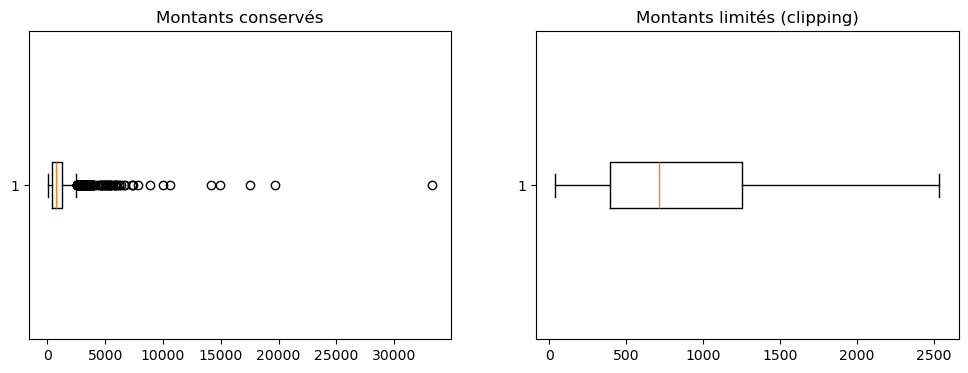

In [22]:
m_ref_clip = m_ref.clip(lower=borne_basse, upper=borne_haute)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].boxplot(m_ref.dropna(), vert=False)
ax[0].set_title("Montants conservés")
ax[1].boxplot(m_ref_clip.dropna(), vert=False)
ax[1].set_title("Montants limités (clipping)")
plt.show()

In [23]:
# Question 18 : les trois scalers sur montant_dh
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

scalers = {
    "MinMax": MinMaxScaler(),
    "Standard": StandardScaler(),
    "Robust": RobustScaler(),
}

res_ref, res_ver = {}, {}
for nom, sc in scalers.items():
    sc.fit(X_ref[["montant_dh"]])                       # fit : référence seulement
    res_ref[nom] = sc.transform(X_ref[["montant_dh"]]).ravel()
    res_ver[nom] = sc.transform(X_ver[["montant_dh"]]).ravel()  # transform seulement

In [24]:
 #  19. Choisissez trois montants habituels et un montant très élevé
import numpy as np
ver = X_ver["montant_dh"].reset_index(drop=True)

# trois montants habituels (proches des quartiles) + le plus élevé
cibles = [ver.quantile(0.25), ver.quantile(0.50), ver.quantile(0.75)]
idx = [(ver - c).abs().idxmin() for c in cibles] + [ver.idxmax()]

tableau = pd.DataFrame({
    "montant_dh": ver.loc[idx].values,
    "MinMax":   np.array(res_ver["MinMax"])[idx],
    "Standard": np.array(res_ver["Standard"])[idx],
    "Robust":   np.array(res_ver["Robust"])[idx],
}, index=["habituel 1", "habituel 2", "habituel 3", "très élevé"])
print(tableau.round(3))

            montant_dh  MinMax  Standard  Robust
habituel 1      366.82   0.010    -0.493  -0.401
habituel 2      684.01   0.019    -0.258  -0.031
habituel 3     1236.11   0.036     0.151   0.613
très élevé    16962.99   0.509    11.789  18.969


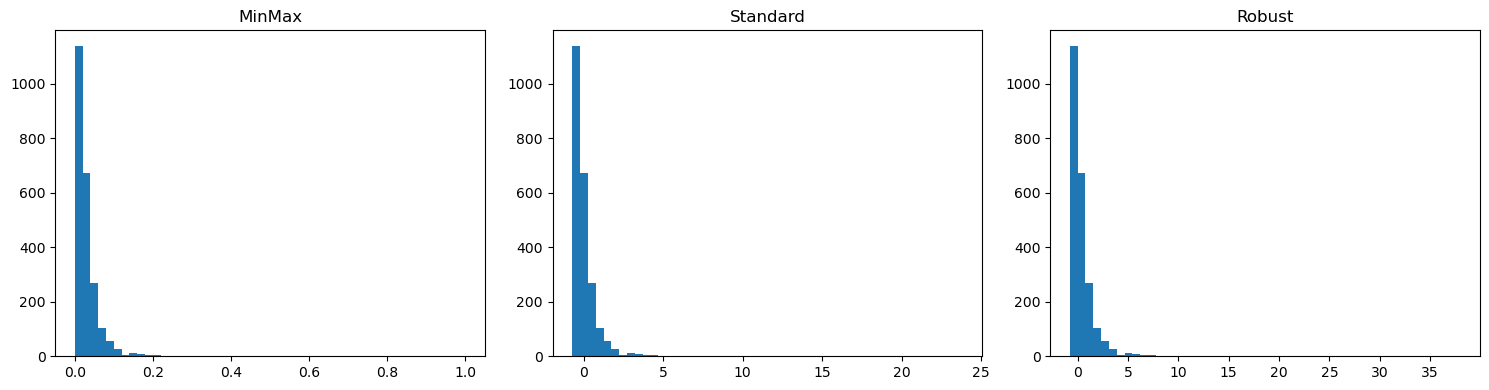

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, nom in zip(ax, ["MinMax", "Standard", "Robust"]):
    a.hist(pd.Series(res_ref[nom]).dropna(), bins=50)
    a.set_title(nom)
plt.tight_layout()
plt.show()

## Partie 4 — Préparer des classes déséquilibrées

In [26]:
from collections import Counter
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

In [27]:
# Question 22 : effectifs et rapport des classes
c_ref = Counter(y_ref)
print(c_ref)

n0, n1 = c_ref[0], c_ref[1]
print(f"Rapport normales / fraudes = {n0} / {n1} = {n0/n1:.1f} pour 1")

Counter({0: 2194, 1: 206})
Rapport normales / fraudes = 2194 / 206 = 10.7 pour 1


In [28]:
# Question 23 : RandomOverSampler (suréchantillonnage)
ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X_ref, y_ref)

print("Avant :", Counter(y_ref))
print("Après :", Counter(y_over))

# Les nouvelles lignes sont-elles des copies ?
print("Lignes dupliquées dans X_over :", X_over.duplicated().sum())

Avant : Counter({0: 2194, 1: 206})
Après : Counter({0: 2194, 1: 2194})
Lignes dupliquées dans X_over : 1988


In [29]:
# 24
rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X_ref, y_ref)

print("Avant :", Counter(y_ref))
print("Après :", Counter(y_under))
print("Lignes conservées :", len(X_under))
print("Lignes supprimées :", len(X_ref) - len(X_under))

Avant : Counter({0: 2194, 1: 206})
Après : Counter({0: 206, 1: 206})
Lignes conservées : 412
Lignes supprimées : 1988


In [30]:
# 25
X_ex = pd.DataFrame({
    "montant": [100, 120, 110, 130, 125, 115, 105, 900, 950, 920],
    "nb_ops":  [1,   2,   1,   2,   1,   2,   1,   8,   9,   7],
})
y_ex = pd.Series([0]*7 + [1]*3)   # 3 fraudes seulement

sm = SMOTE(k_neighbors=2, random_state=42)
X_res, y_res = sm.fit_resample(X_ex, y_ex)

print("Classes après SMOTE :", Counter(y_res))
print("Observations réelles de la classe 1 :")
print(X_ex[y_ex == 1])
print("Observations synthétiques créées :")
print(X_res.iloc[len(X_ex):])

Classes après SMOTE : Counter({0: 7, 1: 7})
Observations réelles de la classe 1 :
   montant  nb_ops
7      900       8
8      950       9
9      920       7
Observations synthétiques créées :
    montant  nb_ops
10      920       8
11      911       7
12      947       8
13      910       7


In [31]:
#27
tableau = pd.DataFrame({
    "Fraude = 0": [Counter(y_ref)[0], Counter(y_over)[0], Counter(y_under)[0], Counter(y_ver)[0]],
    "Fraude = 1": [Counter(y_ref)[1], Counter(y_over)[1], Counter(y_under)[1], Counter(y_ver)[1]],
}, index=["Référence initiale", "Après suréchantillonnage",
          "Après sous-échantillonnage", "Vérification (inchangée)"])
tableau["Total"] = tableau.sum(axis=1)
print(tableau)

                            Fraude = 0  Fraude = 1  Total
Référence initiale                2194         206   2400
Après suréchantillonnage          2194        2194   4388
Après sous-échantillonnage         206         206    412
Vérification (inchangée)           548          52    600


## Partie 5 : Vérifier et enregistrer les données préparées

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

num_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

cat_final = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_final = ColumnTransformer([
    ("num", num_final, num_cols),
    ("cat", cat_final, cat_cols)
])

In [33]:
# fit UNIQUEMENT sur la référence
Xf_ref = preprocessor_final.fit_transform(X_ref)
# transform seulement sur la vérification
Xf_ver = preprocessor_final.transform(X_ver)

print("Référence    :", X_ref.shape, "->", Xf_ref.shape)
print("Vérification :", X_ver.shape, "->", Xf_ver.shape)
print("Même nombre de colonnes :", Xf_ref.shape[1] == Xf_ver.shape[1])

print("NaN dans la référence    :", np.isnan(Xf_ref).sum())
print("NaN dans la vérification :", np.isnan(Xf_ver).sum())

# Les paramètres appris sur la référence
imp = preprocessor_final.named_transformers_["num"].named_steps["imputer"]
sca = preprocessor_final.named_transformers_["num"].named_steps["scaler"]
print("Médianes d'imputation :", dict(zip(num_cols, imp.statistics_.round(2))))
print("Centres (médianes)    :", sca.center_.round(2))
print("Échelles (IQR)        :", sca.scale_.round(2))

print(preprocessor_final.get_feature_names_out())

Référence    : (2400, 8) -> (2400, 18)
Vérification : (600, 8) -> (600, 18)
Même nombre de colonnes : True
NaN dans la référence    : 0
NaN dans la vérification : 0
Médianes d'imputation : {'montant_dh': np.float64(710.79), 'anciennete_mois': np.float64(87.0), 'nb_ops_24h': np.float64(3.0), 'heure': np.float64(11.0)}
Centres (médianes)    : [710.79  87.     3.    11.  ]
Échelles (IQR)        : [816.45  84.     2.    13.  ]
['num__montant_dh' 'num__anciennete_mois' 'num__nb_ops_24h' 'num__heure'
 'cat__canal_agence' 'cat__canal_application' 'cat__canal_site_web'
 'cat__canal_telephone' 'cat__appareil_mobile' 'cat__appareil_ordinateur'
 'cat__appareil_terminal' 'cat__region_Autre'
 'cat__region_Casablanca-Settat' 'cat__region_Draa-Tafilalet'
 'cat__region_Marrakech-Safi' 'cat__region_Souss-Massa'
 'cat__international_non' 'cat__international_oui']


In [34]:
# On prend une ligne de la vérification et on invente un canal jamais vu
ligne_inconnue = X_ver.head(1).copy()
ligne_inconnue["canal"] = "canal_inconnu"

resultat = preprocessor_final.transform(ligne_inconnue)   # pas d'erreur
print("Transformation réussie, forme :", resultat.shape)

# Vérifier que les colonnes one-hot de 'canal' sont toutes à 0
noms = preprocessor_final.get_feature_names_out()
cols_canal = [i for i, n in enumerate(noms) if n.startswith("cat__canal_")]
print("Colonnes canal :", [noms[i] for i in cols_canal])
print("Valeurs        :", resultat[0, cols_canal])   # doit être [0. 0. 0. ...]

Transformation réussie, forme : (1, 18)
Colonnes canal : ['cat__canal_agence', 'cat__canal_application', 'cat__canal_site_web', 'cat__canal_telephone']
Valeurs        : [0. 0. 0. 0.]


In [35]:
import joblib

joblib.dump(preprocessor_final, "preprocessor_final.joblib")
charge = joblib.load("preprocessor_final.joblib")

echantillon = X_ver.head(5)
avant = preprocessor_final.transform(echantillon)
apres = charge.transform(echantillon)

print("Valeurs identiques :", np.allclose(avant, apres))

# Les paramètres sont conservés (rien n'a été recalculé)
imp2 = charge.named_transformers_["num"].named_steps["imputer"]
print("Médianes rechargées identiques :", np.allclose(imp.statistics_, imp2.statistics_))

Valeurs identiques : True
Médianes rechargées identiques : True


In [36]:
print("Doublons retirés          :", n_dup)
print("Valeurs manquantes traitées (référence) :")
print(X_ref.isna().sum()[X_ref.isna().sum() > 0])
print("Montants extrêmes (règle 1,5×IQR)       :", len(extremes))
print("Effectifs référence      :", dict(Counter(y_ref)))
print("Après suréchantillonnage :", dict(Counter(y_over)))
print("Après sous-échantillonnage:", dict(Counter(y_under)))

Doublons retirés          : 45
Valeurs manquantes traitées (référence) :
montant_dh          88
anciennete_mois    104
nb_ops_24h          38
canal              123
appareil            96
region              80
dtype: int64
Montants extrêmes (règle 1,5×IQR)       : 146
Effectifs référence      : {0: 2194, 1: 206}
Après suréchantillonnage : {0: 2194, 1: 2194}
Après sous-échantillonnage: {0: 206, 1: 206}
